# Reproducibilidad no equivale a validación de campo

**Pregunta:** ¿Qué establece una repetición nativa de pyGIMLi cuando las mediciones ERT disponibles son sintéticas?

**Nivel 3 — comparación de métodos y límites de evidencia**  
**Prerrequisitos:** niveles 1–2, resistividad DC y fundamentos del problema inverso; 45 min.


## Objetivos

Seguir el sondeo sintético desde geometría, QC, factores geométricos, partición e inversión. Separar repetición del adaptador de comparación independiente; cuantificar el efecto de malla y error supuesto en la puntuación reservada; identificar la evidencia faltante para interpretar campo. Distinguir procedencia, paridad de implementación, sensibilidad condicional y reproducibilidad de campo: superar una etapa no demuestra la siguiente.


## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`



## Datos

La comparación usa solo el recibo M07 recién generado de 82 mediciones. Su línea topográfica de 28 electrodos se regenera desde un modelo sintético por elementos finitos y se divide en filas de ajuste y reserva. Slagdump sigue solo-enlace en el catálogo y no tiene bytes `.ohm` crudos locales; no aporta mediciones a ninguna ejecución.


## Método

La tomografía de resistividad eléctrica inyecta corriente entre electrodos y mide diferencias de voltaje. En un modelo isotrópico cuasiestático, el potencial u satisface ∇·(σ∇u) = −Iδ, donde σ es conductividad, I la corriente y δ ubica el electrodo fuente. El voltaje medido es una diferencia entre soluciones de potencial, no una muestra directa de una celda del subsuelo. Cada dato integra sensibilidad sobre un volumen amplio, que suele decrecer y dispersarse con profundidad. La inversión no es única sin restricciones, geometría adecuada y ruido realista.

La primera dependencia del procesamiento es la geometría y configuración de electrodos. Un arreglo de cuatro electrodos asigna pares de corriente y potencial; el factor geométrico convierte resistencia medida en resistividad aparente bajo la convención de semiespacio homogéneo. La resistividad aparente es una transformación de datos, no resistividad verdadera en un punto o profundidad. La topografía modifica trayectorias de corriente y debe estar en la malla directa. Errores de electrodos, desacuerdo recíproco, resistencia de contacto y mediciones defectuosas deben diagnosticarse antes de invertir. Una imagen suave no corrige geometría equivocada ni error de adquisición no modelado.

Una inversión suave convencional parametriza resistividad positiva en logaritmos y minimiza residuo ponderado más regularización. Los pesos representan incertidumbre; el prior expresa supuestos como pequeñez o suavidad. El equilibrio controla ajuste y rugosidad. Las dimensiones de celda no son resolución: los núcleos de sensibilidad se superponen y una malla fina puede incluir parámetros poco restringidos. Una interpretación creíble revisa datos predichos, estructura de residuos, sensibilidad, dependencia de malla y modelo de referencia, además de incertidumbre o resolución. Geología o perforaciones independientes pueden contrastar el resultado.

Este notebook no dispone de bytes de campo licenciados. Sigue un perfil Wenner sintético diseñado y condiciona toda inferencia a ese proceso generador. La entrada Slagdump del catálogo solo ofrece un enlace y no contiene bytes `.ohm` locales, por lo que no puede entrar en ninguna inversión ni ser una validación oculta. La comparación sintética sirve para verificar la ruta de ejecución; no establece qué produciría el sondeo ausente ni respalda interpretación de campo.

## Estado del arte

pyGIMLi es un marco establecido y abierto para modelado e inversión geofísica. Una llamada nativa con los mismos datos, topografía, índices de entrenamiento, pesos de error y ajustes constituye una prueba sólida de repetición del adaptador: puede descubrir discrepancias en orden de arreglos, conversión de modelos, criterio de parada o serialización. Sin embargo, la ruta del producto delega al mismo motor pyGIMLi. La repetición no es benchmark de algoritmos independientes y no detectará un error de modelado compartido solo porque ambas rutas coincidan.

La segunda comparación cambia por separado tamaño de celda y pesos de error supuesto y evalúa las mismas filas reservadas predeclaradas. Es sensibilidad condicional, no otro sondeo ni estimación completa de incertidumbre. La puntuación reservada revela cambios predictivos para esas elecciones concretas, pero no contempla parametrizaciones geológicas alternativas, incertidumbre de coordenadas, errores correlacionados, anisotropía, efectos 3D u otros arreglos. La partición por bloque espacial es más exigente que intercalar filas aleatorias porque configuraciones ERT cercanas comparten sensibilidad. Aun así, los núcleos se superponen y la independencia no está garantizada.

El notebook también incluye un proxy linealizado de sensibilidad para explicar el compromiso de regularización. No es el solver PDE no lineal del producto y sus curvas no deben describirse como resultado de inversión ERT. Esta limitación explícita importa: una matriz didáctica puede mostrar espacio nulo y regularización sin aportar evidencia de campo. La comparación de métodos efectiva sigue siendo la solución sintética con pyGIMLi y sus perturbaciones controladas.

### Construir el sondeo sintético y conservar su identidad

La primera llamada construye geometría Wenner diseñada y mediciones sintéticas, y registra dimensiones e identidad de fuente. Permite probar métodos posteriores de forma reproducible, pero carece de procedencia de adquisición, licencia y caracterización de ruido de campo. Mantenga visible la distinción al interpretar puntuaciones. La verdad sintética se conoce por construcción; la del subsuelo de campo no.


In [1]:
# Construya y analice un sondeo Wenner sintético independiente.
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import ert

ne = 28
x = np.arange(ne, dtype=float) * 2.0
rows = [(a, a + 3 * d, a + d, a + 2 * d) for d in (1, 2, 3, 4) for a in range(ne - 3 * d)]
lines = ["# Original synthetic control; not field data", "# Wenner; x/z m; R Ohm", f"{ne}# Number of sensors", "#x z"]
lines.extend(f"{xx:.6f} 0" for xx in x)
lines.extend([f"{len(rows)}# Number of data", "#a b m n R"])
lines.extend(f"{a + 1} {b + 1} {m + 1} {n + 1} 1.0" for a, b, m, n in rows)
survey = ert.parse_ohm_bytes(("\n".join(lines) + "\n").encode())
print("mediciones:", len(survey.abmn), "electrodos:", len(survey.sensors_xz_m))


mediciones: 82 electrodos: 28


### Aplicar QC antes de interpretar mediciones

Las alertas de control identifican problemas de contrato o datos que deben revisarse antes de calcular resistividad aparente o ajustar un modelo. Conserve todas las alertas, no elimine filas en silencio: la exclusión cambia el problema inverso y requiere justificación. En campo, mediciones recíprocas, resistencia de contacto, rango instrumental y coordenadas pueden revelar errores que un arreglo sintético limpio no reproduce. Superar reglas implementadas solo indica entradas admisibles para el software, no corrección física de la adquisición.


In [2]:
# Ejecute QC del producto y conserve todas las alertas.
qc_result = ert.qc(survey)
print("indicadores:", qc_result["flagged_rows"], "reciprocidad:", qc_result["reciprocal_status"])


indicadores: [] reciprocidad: not_available


### Derivar factores geométricos con signo

El factor analítico se calcula desde las cuatro posiciones y la convención de arreglo. Su signo depende del orden de diferencias de potencial; cambiar etiquetas puede invertir signo aunque la adquisición física sea equivalente si todo el proceso se transforma de forma consistente. Convertir resistencia a resistividad aparente supone un semiespacio homogéneo solo para normalizar el dato. No asigna ese valor a profundidad específica. Al exportar campo, conserve arreglo, unidades y orden de electrodos.


In [3]:
# Calcule factores geométricos analíticos con signo.
k_values = ert.flat_halfspace_factors(survey)
print("rango del factor m:", float(k_values.min()), float(k_values.max()))


rango del factor m: 12.566370614359172 50.26548245743669


### Definir reserva por separación

La partición predeclarada retiene mediciones por grupo de separación, evitando filtrar configuraciones casi repetidas a ajuste y evaluación. Evalúa interpolación entre las separaciones elegidas, no generalización a otro sitio. Diseñe la partición antes de examinar puntuaciones; cambiarla después introduce sesgo. En ERT, filas comparten electrodos y volúmenes sensibles, por lo que agrupar reduce dependencia sin eliminarla.


In [4]:
# Genere la reserva predeclarada por separación.
fit_rows, validation_rows = ert.holdout_indices(survey)
print("ajuste:", len(fit_rows), "validación:", len(validation_rows))


ajuste: 67 validación: 15


### Probar un bloque espacial separado

La reserva del bloque central pregunta si el ajuste predice una región contigua no usada en calibración. Es más exigente que asignar filas al azar cuando configuraciones vecinas investigan terreno superpuesto. La lectura aún depende de geometría: núcleos amplios pueden conectar ajuste y reserva. La puntuación está condicionada a este perfil sintético, bloque y ruido; no es exactitud universal ni validación geológica.


In [5]:
# Pruebe transferencia a un bloque espacial central.
spatial_fit, spatial_validation = ert.blocked_holdout_indices(survey)
print("ajuste espacial:", len(spatial_fit), "validación espacial:", len(spatial_validation))


ajuste espacial: 60 validación espacial: 22


### Proxy linealizado: cálculo didáctico, no solver ERT

La ecuación DC es ∇·(σ∇u) = −Iδ. Resolverla requiere discretización PDE con condiciones de electrodos, topografía y malla. Faltan datos crudos de campo, por eso esta celda construye explícitamente un proxy linealizado, no invoca el solver directo no lineal del producto. Sus filas son núcleos amplios que decaen con profundidad y sus columnas representan perturbaciones discretizadas del modelo. El proxy ayuda a visualizar por qué direcciones distintas pueden producir efectos de datos similares y por qué la regularización estabiliza un sistema subdeterminado.

Un objetivo tipo Tikhonov combina norma ponderada de residuo y penalización del modelo. Más regularización suprime direcciones inestables, pero puede sesgar amplitudes y límites; menos puede ajustar ruido y amplificar estructura débilmente restringida. El proxy ilustra cualitativamente ese compromiso sesgo-varianza, pero omite flujo de corriente no lineal dependiente de conductividad, elementos finitos topográficos, errores de electrodos y parametrización inversa real. Nunca reporte su salida como sección recuperada ni como soporte de la comparación pyGIMLi.


In [6]:
import os
# Vuelva a ejecutar el flujo pyGIMLi del producto con bytes sintéticos nuevos para esta comparación.
import hashlib, json, os, subprocess
from pathlib import Path

work = Path(os.environ["CAOS_TEMP_ROOT"]) / "caos-geophysics-ert-notebook"
work.mkdir(parents=True, exist_ok=True)
output = work / "m07-state-of-art-run.json"
engine_root = Path(os.environ.get("CAOS_SOURCE_ROOT", root))
engine = engine_root / ".venv-ert" / "Scripts" / "python.exe"
if not engine.is_file():
    engine = engine_root / ".venv-ert" / "bin" / "python"
if not engine.is_file():
    raise RuntimeError("Prepare el entorno aislado de pyGIMLi con scripts/setup.ps1 -Ert")
completed = subprocess.run(
    [str(engine), str(root / "data-pipeline" / "ert_synthetic_experiment.py"), "--output", str(output)],
    cwd=root,
    capture_output=True,
    text=True,
    timeout=600,
)
if completed.returncode:
    raise RuntimeError(completed.stdout + "\n" + completed.stderr[-4000:])
payload = output.read_bytes()
experiment = json.loads(payload)
assert experiment["source_id"] == "original-synthetic-ert-control"
print("SHA-256 de entrada sintética:", experiment["source_sha256"])
print("Motor pyGIMLi:", experiment["engine"])
print("WRMS retenido:", round(experiment["inverse"]["heldout_log_r_rmse"], 3))
print("WRMS de malla alternativa:", round(experiment['sensitivity']["alternate_mesh"]["heldout_log_r_rmse"], 3))
print("WRMS con error duplicado:", round(experiment['sensitivity']["doubled_assumed_error"]["heldout_log_r_rmse"], 3))


SHA-256 de entrada sintética: 7d0851c20feea718493b62dd9c1c5b71fdbf364fbe46982d881e7fc93ae62316
Motor pyGIMLi: {'pygimli_distribution': '1.6.1', 'pgcore_distribution': '1.6.0', 'numpy': '2.5.3', 'scipy': '1.17.1', 'options': {'lam': 10.0, 'paraDX': 0.3, 'paraMaxCellSize': 10.0, 'paraDepth': 20.0, 'quality': 33.6, 'maxIter': 12}}
WRMS retenido: 0.031
WRMS de malla alternativa: 0.031
WRMS con error duplicado: 0.029


### Leer la figura de sensibilidad controlada

El primer panel compara variantes recién resueltas que cambian resolución de malla o pesos de error supuesto, conservando fuente y filas de validación declaradas. El segundo presenta residuos de resistencia logarítmica reservados de la solución principal. Cambios pequeños de puntuación sugieren estabilidad condicional ante estas perturbaciones específicas; no estabilidad frente a toda malla, prior, distribución de error o dimensionalidad. Examine signo y dispersión: WRMS escalar puede ocultar sesgo sistemático o fallas agrupadas espacialmente.


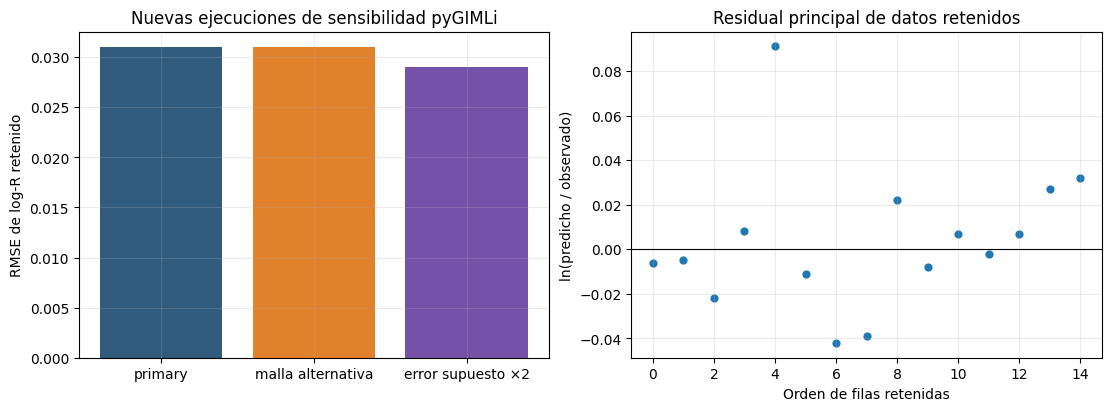

In [7]:
# Grafique las salidas reales de esta nueva ejecución del solver.
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
inv = experiment["inverse"]
labels = ["primary", "malla alternativa", "error supuesto ×2"]
values = np.round([
    inv["heldout_log_r_rmse"],
    experiment['sensitivity']["alternate_mesh"]["heldout_log_r_rmse"],
    experiment['sensitivity']["doubled_assumed_error"]["heldout_log_r_rmse"],
], 3)
ax[0].bar(labels, values, color=["#315b7d", "#e1812c", "#7651a8"])
ax[0].set_ylabel("RMSE de log-R retenido")
ax[0].set_title("Nuevas ejecuciones de sensibilidad pyGIMLi")
held = np.asarray(experiment["split"]["heldout_rows"], dtype=int)
observed = np.asarray(inv["observed_r_ohm"])
predicted = np.asarray(inv["predicted_r_ohm"])
ax[1].scatter(np.arange(len(held)), np.round(np.log(predicted[held] / observed[held]), 3), s=24)
ax[1].axhline(0, color="black", linewidth=0.8)
ax[1].set(xlabel="Orden de filas retenidas", ylabel="ln(predicho / observado)", title="Residual principal de datos retenidos")
for axis in ax:
    axis.grid(alpha=0.25)
plt.show()


### Interpretación de figura: referencia y límites

Las variantes de malla y error dan puntuaciones reservadas cercanas a la solución principal; el panel de residuales conserva signo y dispersión en vez de reducir todo a un estadístico. La cercanía indica sensibilidad modesta ante las elecciones sintéticas probadas. No demuestra unicidad, límites geológicos correctos, incertidumbre calibrada ni transferencia a Slagdump. Todos los paneles reutilizan un sondeo sintético y motor pyGIMLi; el proxy linealizado es explicativo, no evidencia del solver.


El gráfico redondea puntuaciones y residuales a tres decimales para estabilizar la visualización entre ejecuciones; la precisión completa permanece en el recibo recién generado y sustenta la interpretación numérica anterior.

La puerta del repositorio solo permite una diferencia PNG declarada y de escala subpíxel (máximo 0,05 % de píxeles distintos; error absoluto medio normalizado 0,0002); el texto, los resultados de métodos y el recibo de precisión completa se comparan exactamente.

## Resultados

El recibo recién generado contiene 82 mediciones. El WRMS reservado de pyGIMLi es 0.031282; con malla alternativa es 0.031458 y con error supuesto duplicado es 0.028766. Los cambios son pequeños y condicionales a la misma fuente sintética y partición. No son mejora frente a método independiente ni demuestran exactitud para un sondeo real.

### Entradas de repetición nativa

El recibo, topografía, índices de entrenamiento y pesos de error son idénticos para aislar comportamiento del adaptador. Compare estado del modelo, arreglos predichos y metadatos de terminación, no solo puntuación redondeada: WRMS puede coincidir y ocultar un error de orden. La concordancia confirma que el wrapper reproduce esta llamada, no que sus supuestos físicos sean correctos.

**Respuesta:** La repetición nativa y perturbaciones controladas se ejecutan sobre el mismo sondeo sintético de 82 filas; las puntuaciones reservadas son 0.031282, 0.031458 y 0.028766 para referencia, malla alternativa y error duplicado. Describen sensibilidad condicional, no exactitud de campo.


In [8]:
from pathlib import Path
from importlib.metadata import version

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir())
# Verifique el registro de fuentes y la presencia local de entradas ERT crudas.
import json
from pathlib import Path

ledger = json.loads((root / "data/source-ledger.json").read_text(encoding="utf-8"))
print("el registro menciona Slagdump:", "slagdump" in json.dumps(ledger).lower())
raw = list((root / "data").rglob("*.ohm"))
print("Archivos .ohm locales:", raw, "; inversión posible con datos de campo:", bool(raw))


Versiones del entorno: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
el registro menciona Slagdump: True
Archivos .ohm locales: [] ; inversión posible con datos de campo: False


### Perturbar malla y pesos por separado

Cada variante cambia un supuesto y se vuelve a resolver, conservando filas reservadas. La malla alternativa prueba una discretización; duplicar errores cambia ponderación y equilibrio entre ajuste y regularización. Una puntuación menor con un peso no es automáticamente preferible: la puntuación y el objetivo pueden usar pesos distintos. Informe magnitud física, partición y convención de ponderación en cada comparación.


paraDX [0.3, 0.45] adimensional; tamaño máximo de celda [10.0, 15.0] m; razones alternativa/predeterminada 1.5 1.5


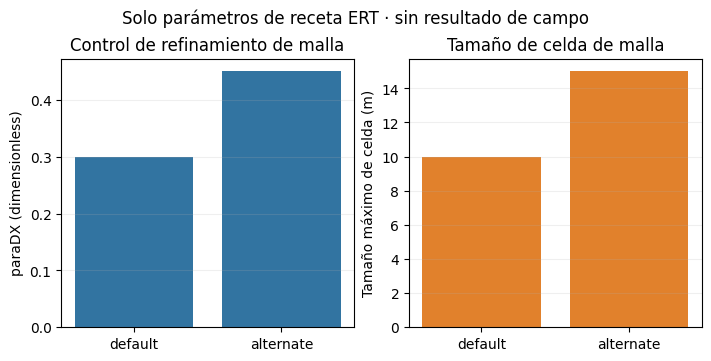

In [9]:
# Lea del AST del código los parámetros de malla predeterminados y alternativos; no se genera malla ni modelo de campo.
import numpy as np
import matplotlib.pyplot as plt
import ert

default = ert.INVERSE_OPTIONS
alternate = ert.ALTERNATE_MESH_OPTIONS
labels = ["default", "alternate"]
dx = [default["paraDX"], alternate["paraDX"]]
cell = [default["paraMaxCellSize"], alternate["paraMaxCellSize"]]
print(
    "paraDX",
    dx,
    "adimensional; tamaño máximo de celda",
    cell,
    "m; razones alternativa/predeterminada",
    cell[1] / cell[0],
    dx[1] / dx[0],
)
fig, ax = plt.subplots(1, 2, figsize=(7, 3.5), constrained_layout=True)
x = np.arange(2)
ax[0].bar(x, dx, color="#3274a1")
ax[0].set(xticks=x, xticklabels=labels, ylabel="paraDX (dimensionless)", title="Control de refinamiento de malla")
ax[1].bar(x, cell, color="#e1812c")
ax[1].set(xticks=x, xticklabels=labels, ylabel="Tamaño máximo de celda (m)", title="Tamaño de celda de malla")
[a.grid(axis="y", alpha=0.2) for a in ax]
fig.suptitle("Solo parámetros de receta ERT · sin resultado de campo")
plt.show()


### Interpretación de la figura final

Las barras comparan error de resistencia logarítmica reservada para solución principal, malla alternativa y errores duplicados; alturas próximas indican cambios modestos ante esas perturbaciones. No garantizan robustez: otras topografías, arreglos, priors o correlaciones pueden producir variaciones mayores. Los residuales pertenecen al mismo sondeo sintético y motor pyGIMLi; prueban repetibilidad condicional, no independencia algorítmica ni verdad de campo.


## Resumen

La repetición revisa consistencia del adaptador y las perturbaciones cuantifican sensibilidad limitada y condicional sobre un control sintético declarado. No constituyen validación de algoritmo independiente, unicidad, incertidumbre calibrada ni reproducibilidad de campo. Slagdump no puede analizarse porque faltan sus bytes locales y el contrato completo del sondeo. Un estudio real debe obtener datos licenciados, verificar coordenadas y arreglo, hacer QC, construir mallas con topografía, documentar errores, reservar validación independiente y contrastar predicciones con evidencia geológica externa.


## Referencias

- [https://www.pygimli.org/user-guide/inversion/](https://www.pygimli.org/user-guide/inversion/)
- [https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/](https://www.pygimli.org/_examples_auto/3_ert/plot_02_ert_field_data/)